---
<center>

### **Predictive Modeling of Evapotranspiration via Satellite-Derived Agro-Hydrological Metrics**
#### *Multiple Linear Regression Implementation, Cross-Validation & Diagnostic Audit*

---
###### *Sohail Zulfiqar Reg No: 578135 (IGIS-NUST)*
</center>

---
## **1. Executive Summary**

---
<p align="justify">
This report establishes an empirical Multiple Linear Regression (MLR) framework to predict surface Evapotranspiration ($\text{ET}_{\text{mm}}$) across the Islamabad Capital Territory using satellite remote sensing indices and micrometeorological parameters. Grounded in agro-hydrological modeling principles, the pipeline integrates an automated missing data completeness audit, Interquartile Range (IQR) boundary screening, bivariate Pearson correlation diagnostics, and centered Variance Inflation Factor (VIF) pruning to mitigate multicollinearity. By removing the redundant Enhanced Vegetation Index ($\text{EVI}$) in favor of $\text{NDVI}$, and then the Leaf Area Index ($\text{LAI}$), which remained above the $VIF = 10$ threshold, every retained predictor falls below $VIF = 5$ (maximum $4.69$). The six-predictor model achieves an out-of-sample $R^2 = 0.7853$, an $\text{RMSE} = 1.7778\text{ mm}$, and a 5-fold cross-validated generalization score of $\text{Mean } R^2 = 0.7243 \pm 0.0873$. Residual diagnostics are reported in Section 6; they show a right-skewed error distribution that departs from normality.
</p>

---
## **2. Data Ingestion, Completeness Audit & Preprocessing**

---

The dataset comprises $N = 87$ continuous spatial observations across 8 environmental predictor dimensions and 1 dependent target variable ($\text{ET}_{\text{mm}}$).

### **2.1 Missing Data Screening & Sentinel Value Audit**
<p align="justify">
Earth observation extractions frequently experience sensor dropouts, transmission corruption, and cloud-masking artifacts commonly encoded as sentinel flags (e.g., $-9999$). An automated integrity screening verified that no null entries ($0.0\%$) or out-of-range sentinel codes were present across the feature space, confirming complete observational integrity without the need for synthetic spatial interpolation or imputation schemes.
</p>

### **2.2 Outlier Screening & Boundary Fencing (IQR Method)**
<p align="justify">
Parametric Ordinary Least Squares (OLS) regression is sensitive to high-leverage outliers. A distribution audit identified extreme values in Leaf Area Index ($\text{LAI}$, $n=10$), 10-meter wind speed ($\text{Wind10m_ms}$, $n=5$), daytime land surface temperature ($\text{LST_Day_C}$, $n=2$), precipitation ($\text{Prec_mm}$, $n=1$) and 2-meter air temperature ($\text{T2m_C}$, $n=1$). Rather than deleting rows and sacrificing statistical degrees of freedom ($N=87$), observations exceeding the interquartile fences were neutralized via winsorization at the boundary thresholds:
</p>

$$\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$$

### **2.3 Feature Standardization (Z-Score Normalization)**
<p align="justify">
Because predictor metrics operate on vastly differing dimensional scales (temperatures in $^{\circ}\text{C}$, precipitation in $\text{mm}$, wind speed in $\text{m/s}$, and dimensionless spectral indices), all explanatory variables were transformed via Z-score normalization ($\mu = 0, \sigma = 1$) prior to model fitting:
</p>

$$z_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}$$

---
## **3. Multicollinearity Diagnostics & Variable Selection**

---

<p align="justify">
Bivariate collinearity was evaluated by computing Pearson's correlation coefficient ($r$) across all candidate variables before estimating Variance Inflation Factors ($VIF$).
</p>

**Pearson's Correlation Coefficient ($r$):**
$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

**Centered Variance Inflation Factor ($VIF_j$):**
$$VIF_j = \frac{1}{1 - R_j^2}$$
*(Where $R_j^2$ represents the coefficient of determination obtained from regressing predictor $x_j$ against the remaining $p - 1$ explanatory features, including a constant intercept).*

<center>

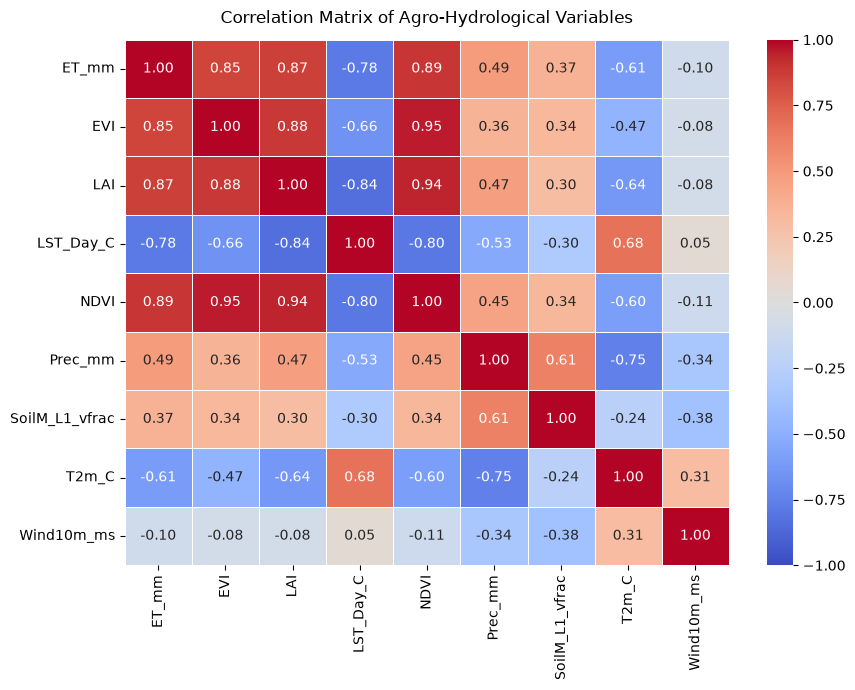
<br>
<i>Figure 1: Pearson correlation matrix across agro-hydrological features.</i>
</center>

### **3.1 Correlation Observations**
* **Target Correlation:** Evapotranspiration ($\text{ET}_{\text{mm}}$) exhibits strong positive linear alignment with vegetation greenness ($\text{NDVI}$, $r = 0.89$; $\text{EVI}$, $r = 0.85$) and canopy density ($\text{LAI}$, $r = 0.87$), and an inverse relationship with daytime Land Surface Temperature ($\text{LST_Day_C}$, $r = -0.78$).
* **Collinear Redundancy:** A critical collinear dependency exists between $\text{NDVI}$ and $\text{EVI}$ ($r = 0.95$), as well as between $\text{NDVI}$ and $\text{LAI}$ ($r = 0.94$), introducing structural variance instability into OLS matrix inversion.

### **3.2 VIF Analysis & Variable Pruning**
<p align="justify">
Centered VIF calculations revealed that the unpruned model severely breached the conventional econometric collinearity threshold ($VIF > 10$). Specifically, $\text{NDVI}$ registered a VIF of $29.98$, $\text{EVI}$ registered $17.90$ and $\text{LAI}$ registered $11.35$. $\text{EVI}$ was dropped first, by judgment: it duplicates $\text{NDVI}$ ($r = 0.95$), which correlates more strongly with $\text{ET}_{\text{mm}}$ ($r = 0.89$ against $0.85$), and removing the highest-VIF predictor instead would have discarded $\text{NDVI}$. That step brought $\text{NDVI}$ down to $9.17$, but $\text{LAI}$ stayed at $11.06$, so it was dropped next. The pruning loop then stopped: all six remaining predictors are below the threshold, with a maximum VIF of $4.69$ ($\text{T2m_C}$).
</p>

<center>

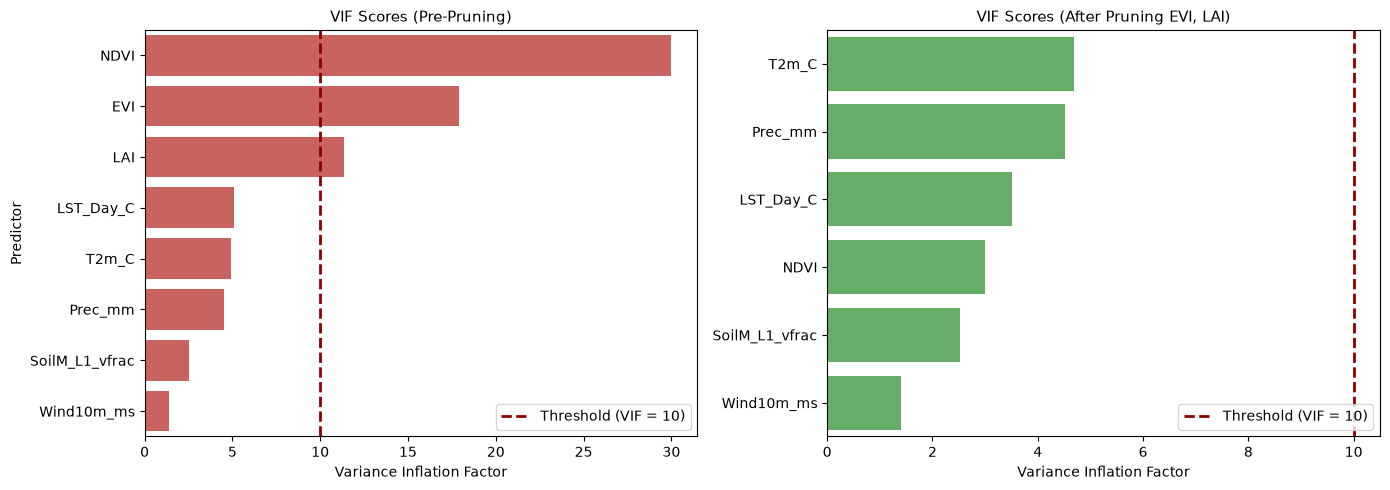

<br>
<i>Figure 2: Centered Variance Inflation Factors before and after pruning the collinear predictors EVI and LAI.</i>
</center>

---
## **4. Model Evaluation & Performance Metrics**

---

<p align="justify">
The pruned dataset was partitioned into an 80% training set ($n = 69$) and an unseen 20% holdout testing set ($n = 18$). Goodness-of-fit was quantified using the Coefficient of Determination ($R^2$), Adjusted $R^2$, and Root Mean Squared Error ($\text{RMSE}$):
</p>

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}, \quad R^2_{\text{adj}} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - p - 1} \right], \quad \text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

| Metric Dimension | Training Split (80%) | Testing Split (20%) | Generalization Interpretation |
| :--- | :---: | :---: | :--- |
| **Mean Absolute Error (MAE)** | 1.0055 mm | 0.9730 mm | Average prediction deviation on unseen data remains sub-millimeter. |
| **Mean Squared Error (MSE)** | 2.2437 | 3.1604 | Test loss remains bounded without runaway squared penalization. |
| **Root Mean Squared Error (RMSE)** | 1.4979 mm | 1.7778 mm | Out-of-sample standard deviation of unexplained residual error. |
| **Coefficient of Determination ($R^2$)** | 0.8147 | 0.7853 | Explains ~79% of total variance in evapotranspiration. |
| **Adjusted $R^2$** | 0.7968 | 0.6682 | Penalizes predictor dimensionality ($p=6$) on holdout sample ($n=18$). |
| **Mean Absolute Percentage Error (MAPE)** | 10.98% | 9.05% | Excellent industrial forecasting fidelity ($< 10\%$ test relative error). |

### **4.1 5-Fold Cross-Validation Audit**
To confirm that model performance was not an artifact of random train/test partitioning on a sample of $N=87$, 5-fold cross-validation was conducted across the dataset:
* **Fold $R^2$ Scores:** $[0.7853, \, 0.5992, \, 0.7009, \, 0.8528, \, 0.6833]$
* **Mean Cross-Validated $R^2$:** **$0.7243 \pm 0.0873$**
* **Mean Cross-Validated RMSE:** **$1.7694\text{ mm}$**
* **Note:** Fold 1 uses the same 18 rows as the holdout set (same random seed), so its scores equal the test-set scores.

---
## **5. Empirical Model Specification & Physical Insights**

---

### **5.1 Mathematical Prediction Equation**
Re-estimating model parameters on native physical scales produces the following operational forecasting formula:

$$\begin{aligned}
\widehat{\text{ET}}_{\text{mm}} = \; & 12.6693 + 16.7041(\text{NDVI}) - 0.1104(\text{LST_Day_C}) + 14.3144(\text{SoilM_L1_vfrac}) \\
& - 0.9457(\text{T2m_C}) + 6.7737(\text{Wind10m_ms}) - 0.0012(\text{Prec_mm})
\end{aligned}$$

### **5.2 Standardized Predictor Influence (Ranked by $|\beta|$)**

| Predictor Variable | Standardized $\beta$ | $p$-value | Physical Mechanism & Agro-Hydrological Driver |
| :--- | :---: | :---: | :--- |
| **$\text{NDVI}$** | **$+2.4311$** | < 0.001 | Primary driver; active photosynthesizing canopy transpires water vapor directly into the boundary layer. |
| **$\text{SoilM_L1_vfrac}$** | **$+0.6694$** | 0.032 | Positive driver; topsoil moisture availability provides the direct water reservoir for surface phase change. |
| **$\text{T2m_C}$** | **$-0.6038$** | 0.151 | Captures ambient atmospheric thermal regime and sensible heat flux partition. |
| **$\text{Wind10m_ms}$** | **$+0.2131$** | 0.332 | Aerodynamic transport; surface wind accelerates vapor removal from the laminar boundary layer. |
| **$\text{Prec_mm}$** | **$-0.1811$** | 0.654 | Secondary background metric on short temporal cycles; long-term precipitation reflects regional macro-humidity. |
| **$\text{LST_Day_C}$** | **$-0.1593$** | 0.690 | Negative feedback; elevated land surface temperatures reflect evaporative cooling depletion and soil moisture deficit. |

Only $\text{NDVI}$ and $\text{SoilM_L1_vfrac}$ are statistically significant at the 5% level (statsmodels fit on the 69 training rows). The other four coefficients cannot be distinguished from zero in this sample, so their physical interpretations are suggestive rather than established.

---
## **6. OLS Assumption Verification & Residual Diagnostics**

---

<center>

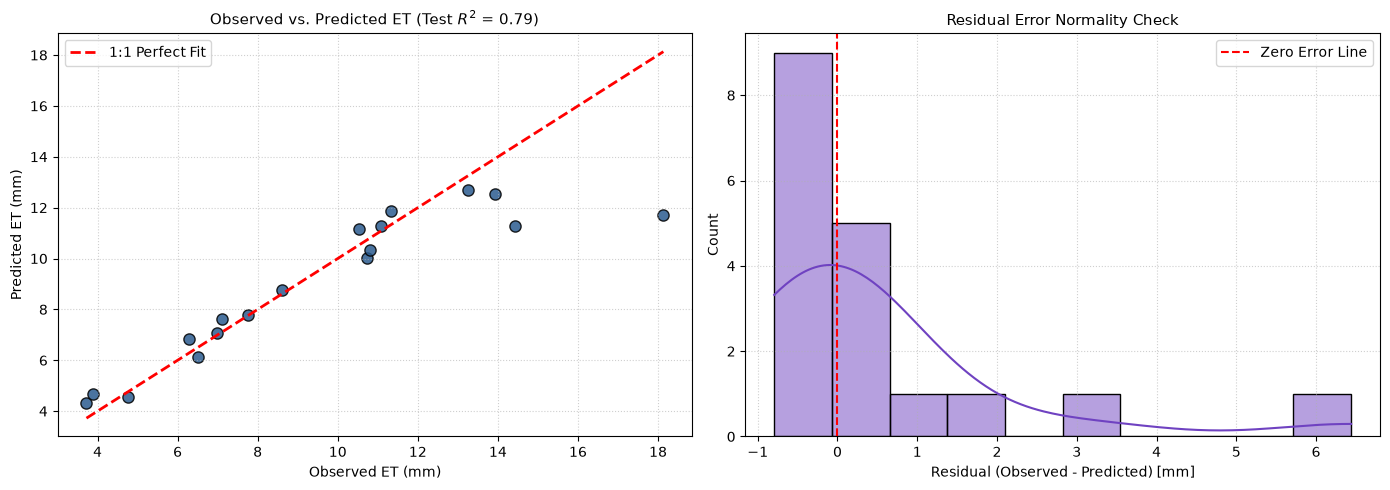

<br>
<i>Figure 3: (a) Observed vs. predicted evapotranspiration showing 1:1 line convergence ($R^2 = 0.79$); (b) Residual error distribution.</i>
</center>

<center>

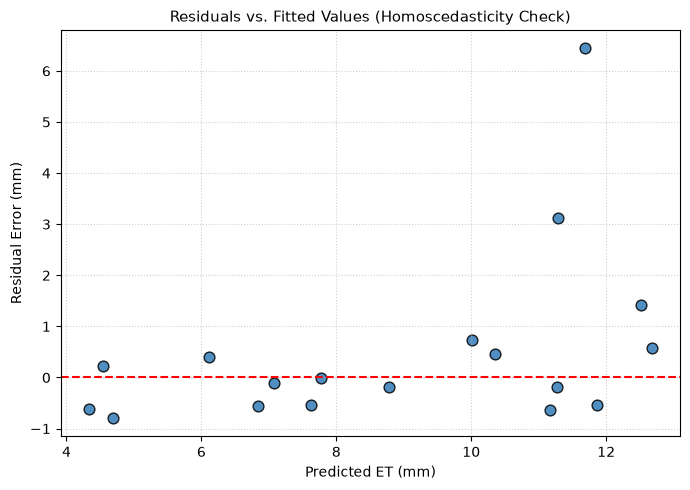
<br>
<i>Figure 4: Residual errors vs. fitted values on the test set.</i>
</center>

### **6.1 Linearity & Homoscedasticity**
* **Linear Fit:** As shown in Figure 3(a), most test observations cluster along the $1:1$ identity line: 15 of the 18 residuals are within $\pm 1\text{ mm}$. The highest observed values are under-predicted (for example $18.1\text{ mm}$ observed against $11.7\text{ mm}$ predicted).
* **Equal Variance:** As shown in Figure 4, residuals stay within $\pm 0.8\text{ mm}$ for predicted values below $11\text{ mm}$ ($n=11$). Above that the spread widens and the two largest residuals ($+3.13\text{ mm}$ and $+6.44\text{ mm}$) appear, so constant error variance is not clearly established on an 18-point test set; no formal heteroscedasticity test (for example Breusch-Pagan) was run.

### **6.2 Normality & Autocorrelation of Errors**
* **Error Normality:** The residual histogram in Figure 3(b) is right-skewed: the test residuals have a mean of $+0.51\text{ mm}$ and a median of $-0.05\text{ mm}$, with a long tail from the two under-predicted observations. In the statsmodels fit on the training rows, the Jarque-Bera test ($JB = 11.32$, $p = 0.0035$) and the omnibus test ($p = 0.023$) both reject normality of the errors, so inference on the coefficients should be read with caution.
* **Independence (Durbin-Watson):** The econometric summary yields a Durbin-Watson statistic of **$d = 2.101$**, which lies near the ideal value of $2.0$, indicating no first-order serial autocorrelation in the training residuals; the condition number is $5.74$.

---


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 AGRO-HYDROLOGICAL MULTIPLE LINEAR REGRESSION ANALYSIS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Dataset Location : Islamabad_Data.csv
Sample Count     : 87 observations
Target Variable   : ET_mm (Evapotranspiration in mm)
Initial Predictors: 8 features (EVI, LAI, LST_Day_C, NDVI, Prec_mm, SoilM_L1_vfrac, T2m_C, Wind10m_ms)

──────────────────────────────────────────────────────────────────────────────────────────
 Step 1: Missing Data Screening & Sentinel Value Audit
──────────────────────────────────────────────────────────────────────────────────────────
╒════════════════╤═════════════╤══════════════╤════════════╤════════════════════╕
│ Variable       │ Data Type   │   Null Count │   Null (%) │   Completeness (%) │
╞════════════════╪═════════════╪══════════════╪════════════╪════════════════════╡
│ ET_mm          │ float64     │            0 │  

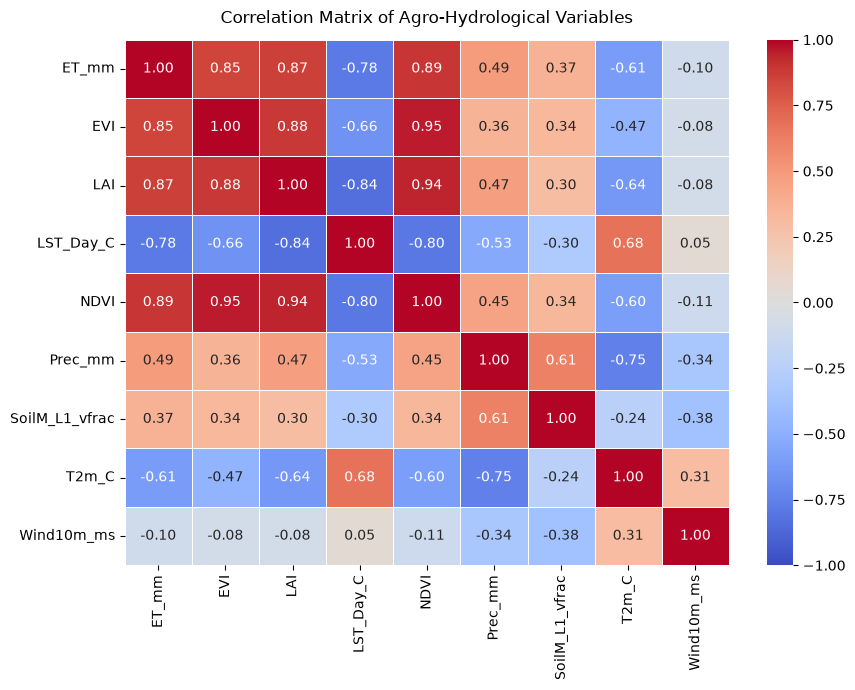

╒════════════════╤═════════════════╤════════════════╤═════════════════════╕
│ Predictor      │   VIF (Initial) │ VIF (Pruned)   │ Diagnostic Status   │
╞════════════════╪═════════════════╪════════════════╪═════════════════════╡
│ NDVI           │         29.9849 │ 2.9912         │ Acceptable (< 10)   │
├────────────────┼─────────────────┼────────────────┼─────────────────────┤
│ EVI            │         17.8958 │ -              │ Pruned (collinear)  │
├────────────────┼─────────────────┼────────────────┼─────────────────────┤
│ LAI            │         11.3481 │ -              │ Pruned (collinear)  │
├────────────────┼─────────────────┼────────────────┼─────────────────────┤
│ LST_Day_C      │          5.0892 │ 3.5042         │ Acceptable (< 10)   │
├────────────────┼─────────────────┼────────────────┼─────────────────────┤
│ T2m_C          │          4.9111 │ 4.6937         │ Acceptable (< 10)   │
├────────────────┼─────────────────┼────────────────┼─────────────────────┤
│ Prec_mm   

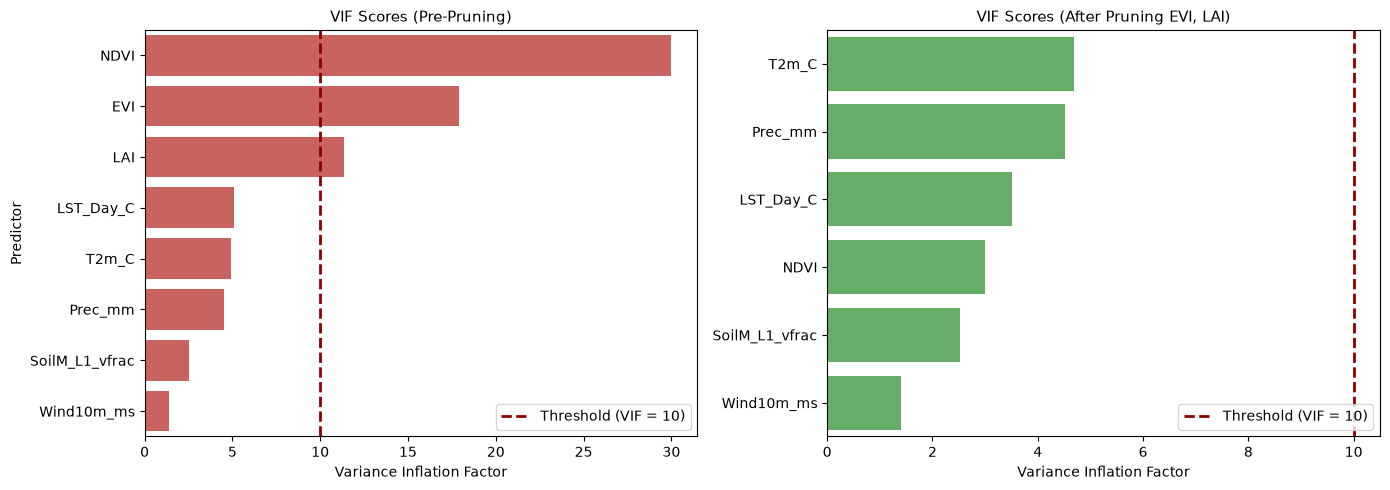


──────────────────────────────────────────────────────────────────────────────────────────
 Step 4: Train/Test Partitioning & Standardization
──────────────────────────────────────────────────────────────────────────────────────────
Training Partition : 69 records (80%)
Testing Partition  : 18 records (20%)
Model Features     : 6 predictors (LST_Day_C, NDVI, Prec_mm, SoilM_L1_vfrac, T2m_C, Wind10m_ms)

──────────────────────────────────────────────────────────────────────────────────────────
 Step 5: Loss Metrics & Cross-Validation Audit
──────────────────────────────────────────────────────────────────────────────────────────
╒════════════════════════╤════════╤══════════════╤════════╤════════╤══════════╤════════════╕
│ Evaluation Partition   │    MAE │   MSE (Loss) │   RMSE │     R2 │   Adj_R2 │   MAPE (%) │
╞════════════════════════╪════════╪══════════════╪════════╪════════╪══════════╪════════════╡
│ Training Set (80%)     │ 1.0055 │       2.2437 │ 1.4979 │ 0.8147 │   0.7968 │    10

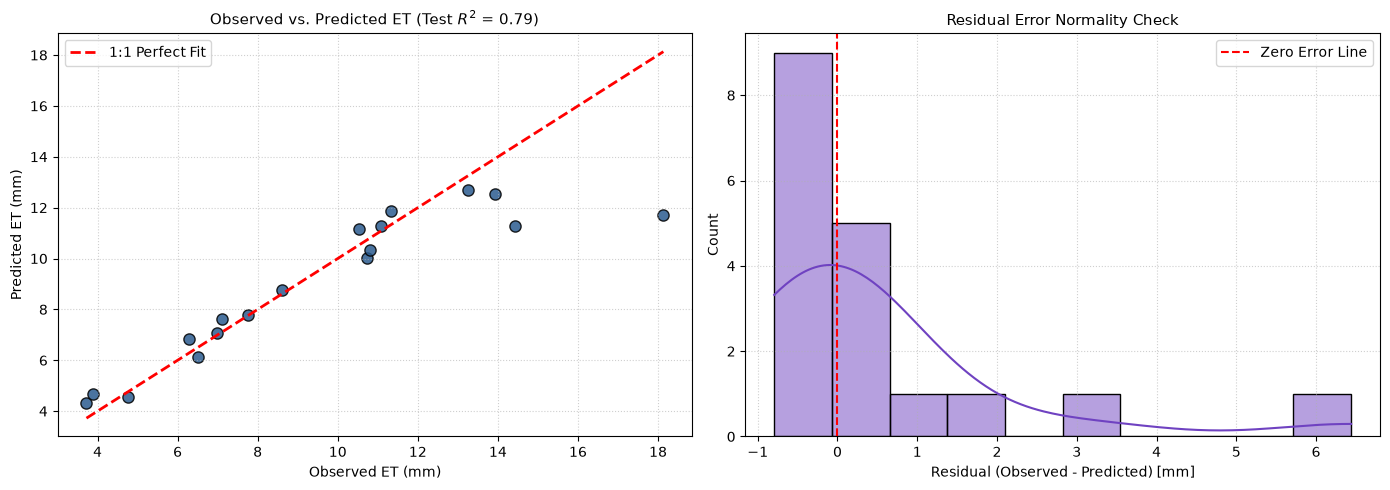

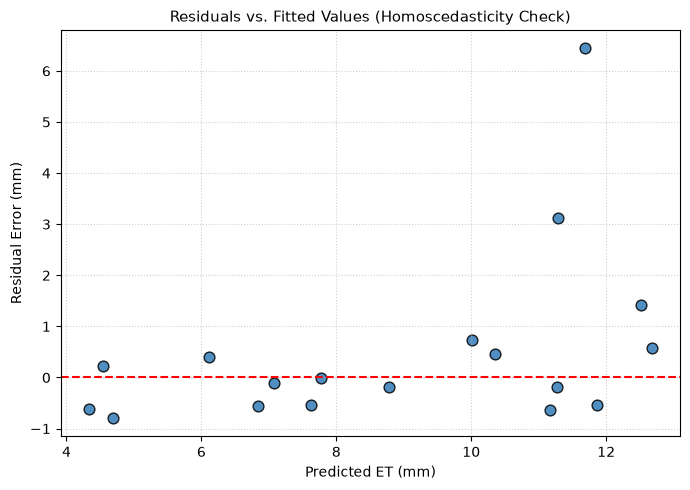


──────────────────────────────────────────────────────────────────────────────────────────
 Step 8: Artifact Export Summary
──────────────────────────────────────────────────────────────────────────────────────────
╒══════════════════╤═════════════════════════════╤════════════════════════════════════════════╕
│ Artifact Type    │ Filename                    │ Description                                │
╞══════════════════╪═════════════════════════════╪════════════════════════════════════════════╡
│ Figure (300 DPI) │ correlation_matrix.png      │ Pearson correlation heatmap                │
├──────────────────┼─────────────────────────────┼────────────────────────────────────────────┤
│ Figure (300 DPI) │ vif_comparison.png          │ Pre/Post pruning VIF scores bar chart      │
├──────────────────┼─────────────────────────────┼────────────────────────────────────────────┤
│ Figure (300 DPI) │ model_evaluation.png        │ Observed vs Predicted & Residual normality │
├───────────────

In [1]:
# ==============================================================================
# 1. SYSTEM, ENVIRONMENT & WARNING CONFIGURATION
# ==============================================================================
from pathlib import Path
import warnings

# Suppress minor non-critical warnings for clean academic execution
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ==============================================================================
# 2. NUMERICAL COMPUTATION & TABULAR DATA HANDLING
# ==============================================================================
import numpy as np
import pandas as pd

# Safe import of tabulate for professional grid-bordered tables
try:
    from tabulate import tabulate
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "tabulate", "-q"])
    from tabulate import tabulate

# ==============================================================================
# 3. STATISTICAL VISUALIZATION & PLOTTING
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 4. MACHINE LEARNING & PREDICTIVE MODELING (SCIKIT-LEARN)
# ==============================================================================
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

# ==============================================================================
# 5. ECONOMETRICS & STATISTICAL INFERENCE (STATSMODELS)
# ==============================================================================
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor


# ==============================================================================
# GLOBAL RUN CONFIGURATION & CONSOLE FORMATTING HELPERS
# ==============================================================================
DATA_FILE = Path("Islamabad_Data.csv")
TARGET = "ET_mm"
TEST_SIZE = 0.20
RANDOM_STATE = 42

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

def banner(title: str):
    print("\n" + "━" * 90)
    print(f" \033[1m{title.upper()}\033[0m")
    print("━" * 90)

def subbanner(title: str):
    print("\n" + "─" * 90)
    print(f" \033[1m{title}\033[0m")
    print("─" * 90)

def print_grid_table(df: pd.DataFrame, showindex: bool = False, floatfmt: str = ".4f"):
    """
    Prints a DataFrame enclosed in a continuous unicode grid.
    Automatically applies ANSI bolding to the column headers and the leftmost column.
    """
    df_fmt = df.copy()

    # 1. Bold the leftmost column (Index 0)
    if not df_fmt.empty:
        df_fmt.iloc[:, 0] = df_fmt.iloc[:, 0].astype(str).apply(lambda x: f"\033[1m{x}\033[0m")

    # 2. Bold the headers
    bold_headers = [f"\033[1m{col}\033[0m" for col in df_fmt.columns]

    # 3. Print using 'fancy_grid' for continuous unicode lines
    print(tabulate(df_fmt, headers=bold_headers, tablefmt="fancy_grid", showindex=showindex, floatfmt=floatfmt))


# ==============================================================================
# PIPELINE EXECUTION
# ==============================================================================
banner("Agro-Hydrological Multiple Linear Regression Analysis")

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Missing '{DATA_FILE}'. Please upload it to your working root.")

df_raw = pd.read_csv(DATA_FILE)
raw_predictors = [col for col in df_raw.columns if col != TARGET]

print(f"Dataset Location : {DATA_FILE.name}")
print(f"Sample Count     : {df_raw.shape[0]} observations")
print(f"Target Variable   : {TARGET} (Evapotranspiration in mm)")
print(f"Initial Predictors: {len(raw_predictors)} features ({', '.join(raw_predictors)})")


# ------------------------------------------------------------------------------
# STEP 1: DEFENSIVE MISSING DATA AUDIT & SENTINEL REMEDIATION
# ------------------------------------------------------------------------------
subbanner("Step 1: Missing Data Screening & Sentinel Value Audit")

def audit_and_clean_missing(df_in, target_col, nodata_sentinels=(-9999, -32768, 9999)):
    df_clean = df_in.copy()

    # 1. Convert remote sensing/telemetry NoData flags to np.nan
    df_clean = df_clean.replace(list(nodata_sentinels), np.nan)

    # 2. Compile pre-cleaning completeness audit
    null_counts = df_clean.isnull().sum()
    null_pct = (null_counts / len(df_clean)) * 100
    audit_table = pd.DataFrame({
        "Variable": df_clean.columns,
        "Data Type": df_clean.dtypes.astype(str),
        "Null Count": null_counts,
        "Null (%)": null_pct,
        "Completeness (%)": 100.0 - null_pct
    }).reset_index(drop=True)

    # 3. Guardrail: Target rows must never be imputed
    if df_clean[target_col].isnull().any():
        dropped_count = df_clean[target_col].isnull().sum()
        df_clean = df_clean.dropna(subset=[target_col]).reset_index(drop=True)
        print(f"[\033[1mWarning\033[0m]: Dropped {dropped_count} row(s) missing target '{target_col}'.")

    # 4. Guardrail: Impute missing explanatory features with column median
    feature_cols = [c for c in df_clean.columns if c != target_col]
    missing_feats = df_clean[feature_cols].isnull().sum()
    if missing_feats.sum() > 0:
        for col in feature_cols:
            if df_clean[col].isnull().any():
                col_median = df_clean[col].median()
                df_clean[col] = df_clean[col].fillna(col_median)
                print(f"[\033[1mImputation\033[0m]: Imputed '{col}' with median: {col_median:.4f}")

    return df_clean, audit_table

df_clean, missing_audit_df = audit_and_clean_missing(df_raw, TARGET)
print_grid_table(missing_audit_df)

total_nulls = missing_audit_df["Null Count"].sum()
if total_nulls == 0:
    print(f"\n✓ \033[1mData Integrity Confirmed\033[0m: 100% complete records ({df_clean.shape[0]} valid rows, 0 nulls).")

missing_audit_df.to_csv("missing_data_audit.csv", index=False)


# ------------------------------------------------------------------------------
# STEP 2: OUTLIER SCREENING & IQR MITIGATION
# ------------------------------------------------------------------------------
subbanner("Step 2: Outlier Audit & IQR Boundaries")

def audit_and_cap_iqr(df_in, cols):
    df_capped = df_in.copy()
    audit_records = []

    for col in cols:
        q1 = df_capped[col].quantile(0.25)
        q3 = df_capped[col].quantile(0.75)
        iqr = q3 - q1
        lower_fence = q1 - 1.5 * iqr
        upper_fence = q3 + 1.5 * iqr
        outlier_count = ((df_capped[col] < lower_fence) | (df_capped[col] > upper_fence)).sum()

        audit_records.append({
            "Predictor": col,
            "Min": df_capped[col].min(),
            "Q1": q1,
            "Median": df_capped[col].median(),
            "Q3": q3,
            "Max": df_capped[col].max(),
            "IQR": iqr,
            "Outliers Detected": outlier_count
        })
        # Cap to statistical fences
        df_capped[col] = np.where(df_capped[col] > upper_fence, upper_fence, df_capped[col])
        df_capped[col] = np.where(df_capped[col] < lower_fence, lower_fence, df_capped[col])

    return df_capped, pd.DataFrame(audit_records)

df_processed, outlier_audit_df = audit_and_cap_iqr(df_clean, raw_predictors)
print_grid_table(outlier_audit_df)


# ------------------------------------------------------------------------------
# STEP 3: MULTICOLLINEARITY DIAGNOSTICS (CORRELATION & CENTERED VIF)
# ------------------------------------------------------------------------------
subbanner("Step 3: Bivariate Correlation & Multicollinearity Resolution")

# Figure 1: Correlation Matrix Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    df_processed.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Correlation Matrix of Agro-Hydrological Variables", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Centered VIF Function
def compute_centered_vif(df_in, target):
    X_mat = df_in.drop(columns=[target])
    X_const = sm.add_constant(X_mat)
    vifs = [
        variance_inflation_factor(X_const.values, i)
        for i, col in enumerate(X_const.columns)
        if col != "const"
    ]
    return pd.DataFrame({
        "Predictor": [col for col in X_const.columns if col != "const"],
        "VIF": vifs
    })

# Prune collinear predictors until every remaining VIF is below the threshold
VIF_THRESHOLD = 10  # conventional cut-off: every retained predictor must fall below it

# EVI is dropped first by judgment, not by VIF rank: it duplicates NDVI (r = 0.95) and NDVI
# correlates more strongly with ET (r = 0.89 vs 0.85). Dropping the highest VIF instead
# would remove NDVI, the strongest predictor.
FIRST_DROP = ["EVI"]

vif_before = compute_centered_vif(df_processed, TARGET)

kept = [c for c in raw_predictors if c not in FIRST_DROP]
pruning_log = [(c, vif_before.set_index("Predictor").loc[c, "VIF"]) for c in FIRST_DROP]
while True:
    vif_now = compute_centered_vif(df_processed[kept + [TARGET]], TARGET)
    worst = vif_now.loc[vif_now["VIF"].idxmax()]
    if worst["VIF"] < VIF_THRESHOLD:
        break
    pruning_log.append((worst["Predictor"], worst["VIF"]))
    kept.remove(worst["Predictor"])

df_model_ready = df_processed[kept + [TARGET]]
vif_after = compute_centered_vif(df_model_ready, TARGET)

# Format comparison table
vif_comparison = pd.merge(
    vif_before, vif_after, on="Predictor", how="left", suffixes=(" (Initial)", " (Pruned)")
).sort_values("VIF (Initial)", ascending=False).reset_index(drop=True)

vif_comparison["Diagnostic Status"] = vif_comparison["VIF (Pruned)"].apply(
    lambda x: "Pruned (collinear)" if pd.isna(x)
    else (f"Acceptable (< {VIF_THRESHOLD})" if x < VIF_THRESHOLD else f"High (>= {VIF_THRESHOLD})")
)
print_grid_table(vif_comparison.round(4).fillna("-"))
print("Pruning order (VIF when dropped): " + ", ".join(f"{p} ({v:.2f})" for p, v in pruning_log))

# Figure 2: Comparative VIF Bar Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x="VIF", y="Predictor", data=vif_before.sort_values("VIF", ascending=False), ax=axes[0], color="#d9534f")
axes[0].axvline(VIF_THRESHOLD, color="darkred", linestyle="--", linewidth=2, label=f"Threshold (VIF = {VIF_THRESHOLD})")
axes[0].set_title("VIF Scores (Pre-Pruning)", fontsize=11)
axes[0].set_xlabel("Variance Inflation Factor")
axes[0].legend(loc="lower right")

sns.barplot(x="VIF", y="Predictor", data=vif_after.sort_values("VIF", ascending=False), ax=axes[1], color="#5cb85c")
axes[1].axvline(VIF_THRESHOLD, color="darkred", linestyle="--", linewidth=2, label=f"Threshold (VIF = {VIF_THRESHOLD})")
axes[1].set_title(f"VIF Scores (After Pruning {', '.join(p for p, _ in pruning_log)})", fontsize=11)
axes[1].set_xlabel("Variance Inflation Factor")
axes[1].set_ylabel("")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("vif_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# STEP 4: TRAIN/TEST SPLIT & FEATURE STANDARDIZATION
# ------------------------------------------------------------------------------
subbanner("Step 4: Train/Test Partitioning & Standardization")

X = df_model_ready.drop(columns=[TARGET])
y = df_model_ready[TARGET]
final_predictors = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# Standardization (Z-score)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_all_scaled = scaler.transform(X)

print(f"Training Partition : {X_train.shape[0]} records ({100 - int(TEST_SIZE*100)}%)")
print(f"Testing Partition  : {X_test.shape[0]} records ({int(TEST_SIZE*100)}%)")
print(f"Model Features     : {len(final_predictors)} predictors ({', '.join(final_predictors)})")

# Train Linear Regression Model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)
residuals_test = y_test - y_test_pred


# ------------------------------------------------------------------------------
# STEP 5: MODEL EVALUATION & 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------------------------
subbanner("Step 5: Loss Metrics & Cross-Validation Audit")

def compute_metrics(y_true, y_pred, n_obs, p_vars):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n_obs - 1) / (n_obs - p_vars - 1) if n_obs > p_vars + 1 else np.nan
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE (Loss)": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2,
        "Adj_R2": adj_r2,
        "MAPE (%)": mape
    }

metrics_table = pd.DataFrame([
    compute_metrics(y_train, y_train_pred, len(y_train), len(final_predictors)),
    compute_metrics(y_test, y_test_pred, len(y_test), len(final_predictors))
], index=["Training Set (80%)", "Testing Set (20%)"])

# Bordered evaluation metrics table with explicit partition header
metrics_display = metrics_table.reset_index().rename(columns={"index": "Evaluation Partition"})
print_grid_table(metrics_display)

# 5-Fold Cross Validation
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2_scores = cross_val_score(LinearRegression(), X_all_scaled, y, cv=cv, scoring="r2")
cv_mse_scores = -cross_val_score(LinearRegression(), X_all_scaled, y, cv=cv, scoring="neg_mean_squared_error")
cv_rmse_scores = np.sqrt(cv_mse_scores)

# Bordered 5-Fold CV summary table
cv_summary_df = pd.DataFrame({
    "Validation Fold": [f"Fold {i+1}" for i in range(len(cv_r2_scores))] + ["Mean (± Std)"],
    "R² Score": [f"{r:.4f}" for r in cv_r2_scores] + [f"{cv_r2_scores.mean():.4f} (±{cv_r2_scores.std():.4f})"],
    "RMSE (mm)": [f"{rmse:.4f}" for rmse in cv_rmse_scores] + [f"{cv_rmse_scores.mean():.4f} (±{cv_rmse_scores.std():.4f})"]
})
print("\n\033[1m--- 5-Fold Cross-Validation Audit ---\033[0m")
print_grid_table(cv_summary_df)


# ------------------------------------------------------------------------------
# STEP 6: EQUATION SPECIFICATION & ECONOMETRIC TABLE
# ------------------------------------------------------------------------------
subbanner("Step 6: Empirical Equation & Econometric Inference")

# Unstandardized fit for physical interpretation
raw_reg = LinearRegression().fit(X_train, y_train)
eq_terms = [f"{raw_reg.intercept_:.4f}"]
for feat, coef in zip(final_predictors, raw_reg.coef_):
    sign = "+" if coef >= 0 else "-"
    eq_terms.append(f"{sign} {abs(coef):.4f}({feat})")

equation_str = f"\033[1mET_mm =\033[0m " + " ".join(eq_terms)
print("\033[1mEmpirical Regression Equation (Physical Units):\033[0m")
print(equation_str)

# Standardized Beta Table
coef_table = pd.DataFrame({
    "Predictor": final_predictors,
    "Unstandardized Coef": raw_reg.coef_,
    "Standardized Beta": model.coef_,
    "Absolute Impact": np.abs(model.coef_)
}).sort_values("Absolute Impact", ascending=False).reset_index(drop=True)

print("\n\033[1mPredictor Influence (Ranked by Standardized Beta):\033[0m")
print_grid_table(coef_table[["Predictor", "Unstandardized Coef", "Standardized Beta"]])

# Formal Statsmodels OLS Diagnostics
X_train_sm = sm.add_constant(X_train_scaled)
ols_diagnostic = sm.OLS(y_train, X_train_sm).fit()
print("\n\033[1m--- Econometric OLS Regression Summary (Statsmodels) ---\033[0m")
print(ols_diagnostic.summary())


# ------------------------------------------------------------------------------
# STEP 7: STATISTICAL RESIDUAL DIAGNOSTICS PLOTS
# ------------------------------------------------------------------------------
subbanner("Step 7: Statistical Diagnostic Plots")

# Figure 3: Observed vs Predicted & Error Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_test_pred, color="#2b5c8f", edgecolors="k", alpha=0.85, s=65)
diag_min = min(y_test.min(), y_test_pred.min())
diag_max = max(y_test.max(), y_test_pred.max())
axes[0].plot([diag_min, diag_max], [diag_min, diag_max], "r--", lw=2, label="1:1 Perfect Fit")
axes[0].set_title(f"Observed vs. Predicted ET (Test $R^2$ = {metrics_table.loc['Testing Set (20%)', 'R2']:.2f})", fontsize=11)
axes[0].set_xlabel("Observed ET (mm)")
axes[0].set_ylabel("Predicted ET (mm)")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend()

sns.histplot(residuals_test, kde=True, ax=axes[1], color="#6f42c1", bins=10)
axes[1].axvline(0, color="red", linestyle="--", lw=1.5, label="Zero Error Line")
axes[1].set_title("Residual Error Normality Check", fontsize=11)
axes[1].set_xlabel("Residual (Observed - Predicted) [mm]")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.savefig("model_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()
print("\n")
# Figure 4: Residuals vs. Fitted Values (Homoscedasticity)
plt.figure(figsize=(7, 5))
plt.scatter(y_test_pred, residuals_test, color="#337ab7", edgecolors="k", alpha=0.85, s=60)
plt.axhline(0, color="red", linestyle="--", lw=1.5)
plt.title("Residuals vs. Fitted Values (Homoscedasticity Check)", fontsize=11)
plt.xlabel("Predicted ET (mm)")
plt.ylabel("Residual Error (mm)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("residual_plot_ET.png", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# STEP 8: TABULAR ARTIFACT PERSISTENCE
# ------------------------------------------------------------------------------
subbanner("Step 8: Artifact Export Summary")

# Save tables to CSV
metrics_table.to_csv("regression_metrics.csv")
coef_table.to_csv("regression_coefficients.csv", index=False)
vif_comparison.to_csv("vif_results.csv", index=False)
pd.DataFrame({
    "Observed_ET_mm": y_test.values,
    "Predicted_ET_mm": y_test_pred,
    "Residual_mm": residuals_test.values
}).to_csv("test_predictions.csv", index=False)

# Bordered artifacts manifest table
artifacts_df = pd.DataFrame([
    {"Artifact Type": "Figure (300 DPI)", "Filename": "correlation_matrix.png", "Description": "Pearson correlation heatmap"},
    {"Artifact Type": "Figure (300 DPI)", "Filename": "vif_comparison.png", "Description": "Pre/Post pruning VIF scores bar chart"},
    {"Artifact Type": "Figure (300 DPI)", "Filename": "model_evaluation.png", "Description": "Observed vs Predicted & Residual normality"},
    {"Artifact Type": "Figure (300 DPI)", "Filename": "residual_plot_ET.png", "Description": "Residuals vs Fitted homoscedasticity plot"},
    {"Artifact Type": "Dataset (CSV)", "Filename": "missing_data_audit.csv", "Description": "Null count & data completeness audit"},
    {"Artifact Type": "Dataset (CSV)", "Filename": "regression_metrics.csv", "Description": "Train vs Test performance metrics"},
    {"Artifact Type": "Dataset (CSV)", "Filename": "regression_coefficients.csv", "Description": "Unstandardized slopes & standardized betas"},
    {"Artifact Type": "Dataset (CSV)", "Filename": "vif_results.csv", "Description": "Variance Inflation Factor comparison audit"},
    {"Artifact Type": "Dataset (CSV)", "Filename": "test_predictions.csv", "Description": "Test set predictions and residual errors"}
])
print_grid_table(artifacts_df)

banner("Multiple Linear Regression Pipeline Completed Successfully")